In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from gsec_data import build_table, load_fbil

os.makedirs("images", exist_ok=True)
table = build_table("data")
print(table.shape)

(32, 9)


In [2]:
spreads = pd.DataFrame({
    "2s5s": (table[5] - table[2]) * 100,
    "2s10s": (table[10] - table[2]) * 100,
    "5s10s": (table[10] - table[5]) * 100,
    "10s30s": (table[30] - table[10]) * 100,
})
spreads.round(1).tail(12)

,2s5s,2s10s,5s10s,10s30s
date,,,,
2026-09-25,46.8,69.4,22.6,43.8
2026-10-01,27.8,51.7,23.9,42.7
2026-10-05,34.3,58.0,23.7,43.4
2026-10-06,45.6,64.5,18.9,42.9
2026-10-07,41.9,63.1,21.2,38.4
2026-10-08,49.5,78.9,29.4,36.6
2026-10-09,49.9,81.4,31.6,33.6
2026-10-12,56.7,80.3,23.5,35.9
2026-10-13,63.3,82.4,19.1,39.0


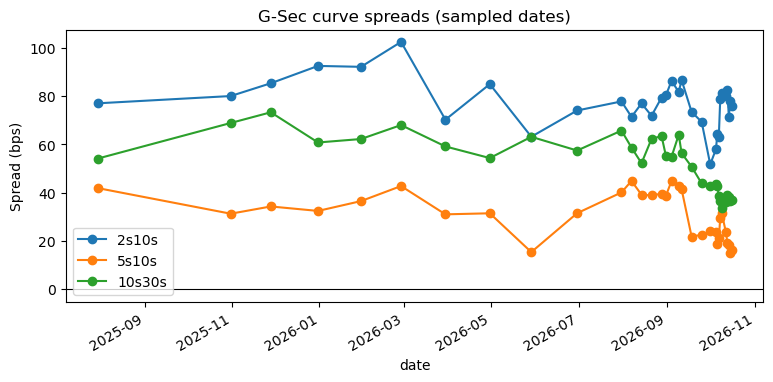

In [3]:
spreads[["2s10s", "5s10s", "10s30s"]].plot(marker="o", figsize=(9, 4))
plt.ylabel("Spread (bps)")
plt.title("G-Sec curve spreads (sampled dates)")
plt.axhline(0, color="black", linewidth=0.8)
plt.savefig("images/spreads.png", dpi=150, bbox_inches="tight")
plt.show()

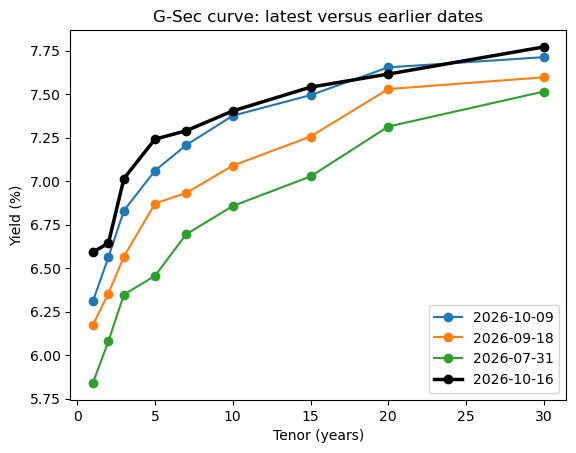

In [4]:
latest = table.index[-1]
compare_dates = ["2026-10-09", "2026-09-18", "2026-07-31"]

for d in compare_dates:
    plt.plot(table.columns, table.loc[d], marker="o", label=d)
plt.plot(table.columns, table.loc[latest], marker="o", color="black",
         linewidth=2.5, label=str(latest.date()))
plt.xlabel("Tenor (years)")
plt.ylabel("Yield (%)")
plt.title("G-Sec curve: latest versus earlier dates")
plt.legend()
plt.savefig("images/curve_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

       2026-10-09  2026-09-18  2026-07-31
tenor                                    
1            28.4        42.0        75.2
2             8.1        28.8        56.4
3            18.4        44.8        66.7
5            18.1        37.0        78.5
7             8.3        35.7        59.5
10            2.7        31.4        54.6
15            4.6        28.4        51.3
20           -3.8         8.6        30.2
30            5.9        17.5        25.7


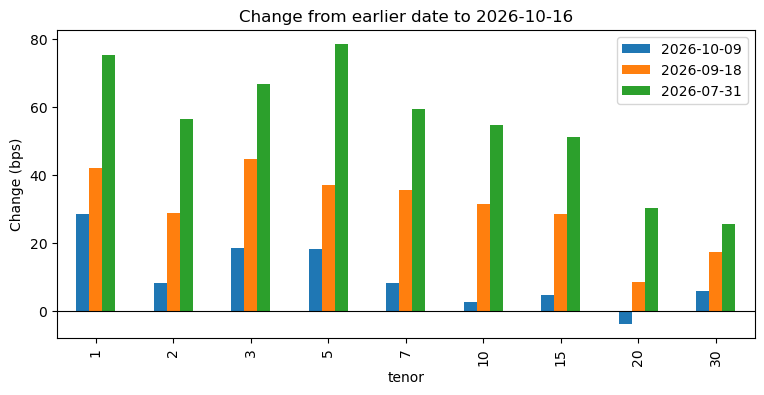

In [5]:
chg = pd.DataFrame({d: (table.loc[latest] - table.loc[d]) * 100
                    for d in compare_dates}).round(1)
chg.index.name = "tenor"
print(chg)
chg.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Change (bps)")
plt.title(f"Change from earlier date to {latest.date()}")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

In [6]:
def bonds_near(date_str, lo, hi):
    d, b = load_fbil(f"data/fbil_{date_str}.xlsx")
    b = b[(b["years"] >= lo) & (b["years"] <= hi)].sort_values("years")
    print(date_str, f"({lo} to {hi} years)")
    print(b[["isin", "years", "ytm", "remark1", "remark2"]].round(3).to_string(index=False))

bonds_near("2026-10-13", 0.5, 4)
bonds_near("2026-10-14", 0.5, 4)
bonds_near("2026-10-12", 14, 26)
bonds_near("2026-10-13", 14, 26)

2026-10-13 (0.5 to 4 years)
        isin  years   ytm     remark1 remark2
IN0020170026  0.586 6.184         NaN     NaN
IN0020240043  0.619 6.392         NaN     NaN
IN0020220037  0.684 6.208         NaN     NaN
IN0020070036  0.802 6.612         NaN     NaN
IN0020070069  0.939 6.552         NaN     NaN
IN0020240167  1.155 6.632         NaN     NaN
IN0020170174  1.238 6.536         NaN     NaN
IN0020220136  1.290 6.548         NaN     NaN
IN0020020247  1.448 6.519         NaN     NaN
IN0020230010  1.492 6.446 Input Point     NaN
IN0020140011  1.637 6.551         NaN     NaN
IN0020030022  1.643 6.505         NaN     NaN
IN0020250034  1.714 6.525         NaN     NaN
IN0020230101  2.029 6.572         NaN     NaN
IN0020230143  2.086 6.637         NaN     NaN
IN0020180454  2.256 6.713         NaN     NaN
IN0020250125  2.292 6.838         NaN      YC
IN0020150069  2.434 6.838         NaN      YC
IN0020220011  2.513 6.838         NaN      YC
IN0020240050  2.639 6.838 Input Point     NaN
IN0020

In [7]:
for d in ["2026-09-18", "2026-10-16"]:
    print(d, spreads.loc[d].round(1).to_dict())

2026-09-18 {'2s5s': 51.7, '2s10s': 73.5, '5s10s': 21.8, '10s30s': 50.8}
2026-10-16 {'2s5s': 59.8, '2s10s': 76.0, '5s10s': 16.2, '10s30s': 36.8}
